In [1]:
# %pip install pandas
# %pip install numpy
# %pip install matplotlib
# %pip install seaborn
# %pip install warnings
# %pip install yaml

In [20]:
%pip install spicy

   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   -- ------------------------------------- 1.8/36.7 MB 14.3 MB/s eta 0:00:03
   ---------- ----------------------------- 10.0/36.7 MB 29.5 MB/s eta 0:00:01
   ------------------- -------------------- 17.8/36.7 MB 32.1 MB/s eta 0:00:01
   --------------------------- ------------ 25.2/36.7 MB 33.9 MB/s eta 0:00:01
   ----------------------------------- ---- 32.8/36.7 MB 34.7 MB/s eta 0:00:01
   ---------------------------------------- 36.7/36.7 MB 31.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
#librerias basicas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.options.display.max_columns=None
import yaml

pd.options.display.max_rows=None    

In [42]:
from scipy.stats import mannwhitneyu, chi2_contingency
from statsmodels.stats.multitest import multipletests

In [43]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

In [17]:
import importlib

In [18]:
from pathlib import Path

In [10]:
pwd

'c:\\Users\\Alberto\\Desktop\\Ing. Estadística\\cursos importantes\\Ciencia de datos (DENIS)\\S3\\exp_proyecto_prueba\\notebooks'

In [5]:
#nombre de proyecto
nombre_exp='exp_proyecto_prueba' #colocar nombre de la carepta que contiene el proyecto

In [19]:
##ruta actual
ruta_actual = Path.cwd()
#Buscar la carpeta del proyecto en la ruta actual
partes = ruta_actual.parts
ruta_raiz = ruta_actual
for i, p in enumerate(partes):
    if p == nombre_exp:
        ruta_raiz = Path(*partes[:i + 1])
        break
ruta_raiz = str(ruta_raiz)

In [7]:
ruta_raiz

'c:\\Users\\Alberto\\Desktop\\Ing. Estadística\\cursos importantes\\Ciencia de datos (DENIS)\\S3\\exp_proyecto_prueba'

In [20]:
#cargando metadata archivo configuracion .yaml
config_path = Path(ruta_raiz) / 'config' / 'model' / 'archivo_config.yaml'
with open(config_path, 'r', encoding='utf-8') as file:
    config = yaml.safe_load(file)


In [21]:
###permite cargar modulos scripts.py
import sys
import os
dir=os.path.abspath(config['settings']['ruta_src'])
if dir not in sys.path:
    sys.path.append(dir)

In [22]:
from prep_EDA import validar_numerico

In [13]:
#recarga modulo cargado en memoria para no reiniciar kernel
# importlib.reload(sys.modules['prep_detect_asimetria'])

In [46]:
#rutas data
path_data_pro=config['settings']['ruta_data_pro']
path_raiz=config['settings']['ruta_raiz']
path_data_raw=config['settings']['ruta_data_raw']
path_data_final=config['settings']['ruta_data_final']
path_models=config['settings']['ruta_models']

In [48]:
df = pd.read_csv(path_data_raw + "/base_churn_telcov2.csv")

In [49]:
df.head()

,PERIODO,CUSTOMER_ID,ANTIGUEDAD_MESES,EDAD_CLIENTE,VELOCIDAD_PLAN,RENTA_MENSUAL,CONSUMO_GB,RECLAMOS_3M,RECLAMOS_12M,TICKETS_TECNICOS,CAIDAS_SERVICIO,DIAS_MORA,PAGOS_ATRASADOS_12M,SATISFACCION,VISITAS_WEB,VISITAS_APP,CAMPANIAS_RECIBIDAS,CAMPANIAS_RESPONDIDAS,VELOCIDAD_REAL,USO_STREAMING,USO_GAMING,N_PRODUCTOS,TENURE_ULTIMO_UPGRADE,INGRESO_HOGAR,COMPETENCIA_ZONA,SCORE_RIESGO,CONTACTOS_CALLCENTER,INTERACCIONES_DIGITALES,VELOCIDAD_VARIABILIDAD,DESCUENTO_PCT,USO_NOCTURNO,USO_FIN_SEMANA,SEGMENTO,TECNOLOGIA,REGION,SEXO,CANAL_VENTA,CHURN_VOLUNTARIO,DISTRITO,FLAG_PREMIUM_FALSO,RENTA_MENSUAL_2,FLAG_RETENCION_EXITOSA,YEAR,FLAG_EMPRESA,FLAG_CASI_CONSTANTE,RENTA_MENSUAL_3,ID_CONTRATO,RECLAMOS_RED_SOCIAL
0,2023-01-01,CUST_000001,113,71.0,50,4.104834,367.997453,2,3,1,0,0,2,7.527282,21,11,7,1,41.457487,53,52,2,48,3876.011607,2,0.253798,3,7,4.408812,36.683128,99.827743,78.052058,Masivo,Fibra,Lima,M,Call Center,0,DIST_388,1,9.349668,0,2023,1,1,5.200272,CONT_0,0.302734
1,2023-02-01,CUST_000001,114,71.0,50,1.757508,323.404792,2,6,1,0,3,3,8.790275,14,11,3,2,150.000000,96,5,2,40,3619.095364,2,0.591510,1,7,24.756448,5.708874,30.954199,56.910698,Masivo,Fibra,Lima,M,Call Center,0,DIST_233,1,-1.562136,0,2023,1,1,0.909783,CONT_1,1.886790
2,2023-03-01,CUST_000001,115,71.0,50,6.830930,385.972005,1,4,1,0,5,1,6.531012,11,6,3,2,53.427387,34,37,2,34,NaN,2,0.601026,3,6,27.236718,14.527568,28.715226,50.073491,Masivo,Fibra,Lima,M,Call Center,0,DIST_121,1,9.173178,1,2023,1,1,3.388333,CONT_2,1.073655
3,2023-04-01,CUST_000001,116,71.0,50,-11.446290,363.553714,3,5,1,6,2,2,7.767388,14,15,1,1,40.719442,53,89,2,16,3690.253173,2,0.958565,3,6,0.767369,31.868347,60.014048,71.092964,Masivo,Fibra,Lima,M,Call Center,0,DIST_203,1,-15.310123,0,2023,1,1,-9.044153,CONT_3,2.436723
4,2023-05-01,CUST_000001,117,71.0,50,-11.588707,390.446332,1,3,0,1,4,1,6.245754,11,15,4,4,NaN,74,84,2,29,NaN,2,0.764246,1,7,9.918989,3.612742,56.265412,47.904073,Masivo,Fibra,Lima,M,Call Center,0,DIST_87,1,-8.563236,0,2023,1,1,-11.721606,CONT_4,0.047751


In [29]:
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
from scipy.stats import ks_2samp

import warnings
warnings.filterwarnings("ignore")

TARGET = "CHURN_VOLUNTARIO"
ID_COL = "CUSTOMER_ID"
DATE_COL = "PERIODO"

df[DATE_COL] = pd.to_datetime(df[DATE_COL])

num_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

cat_cols = df.select_dtypes(
    include=["object","category"]
).columns.tolist()

# excluir target y id

num_cols = [
    c for c in num_cols
    if c != TARGET
]

cat_cols = [
    c for c in cat_cols
    if c != ID_COL
]

In [30]:
#1. Cantidad de variables y filas
print("Filas :", len(df))
print("Columnas :", len(df.columns))

print("\nVariables Numéricas")
print(len(num_cols))

print("\nVariables Categóricas")
print(len(cat_cols))

Filas : 23626
Columnas : 48

Variables Numéricas
38

Variables Categóricas
7


In [31]:
#2. Análisis de nulos
nulos = pd.DataFrame({

    "feature":df.columns,

    "nulos":
        df.isnull().sum(),

    "pct_nulos":
        round(
            100*df.isnull().mean(),
            2
        )

})

nulos.sort_values(
    "pct_nulos",
    ascending=False
)

,feature,nulos,pct_nulos
VELOCIDAD_REAL,VELOCIDAD_REAL,9392,39.75
INGRESO_HOGAR,INGRESO_HOGAR,4522,19.14
EDAD_CLIENTE,EDAD_CLIENTE,2313,9.79
SATISFACCION,SATISFACCION,60,0.25
VELOCIDAD_PLAN,VELOCIDAD_PLAN,0,0.00
RENTA_MENSUAL,RENTA_MENSUAL,0,0.00
CUSTOMER_ID,CUSTOMER_ID,0,0.00
PERIODO,PERIODO,0,0.00
RECLAMOS_3M,RECLAMOS_3M,0,0.00
RECLAMOS_12M,RECLAMOS_12M,0,0.00


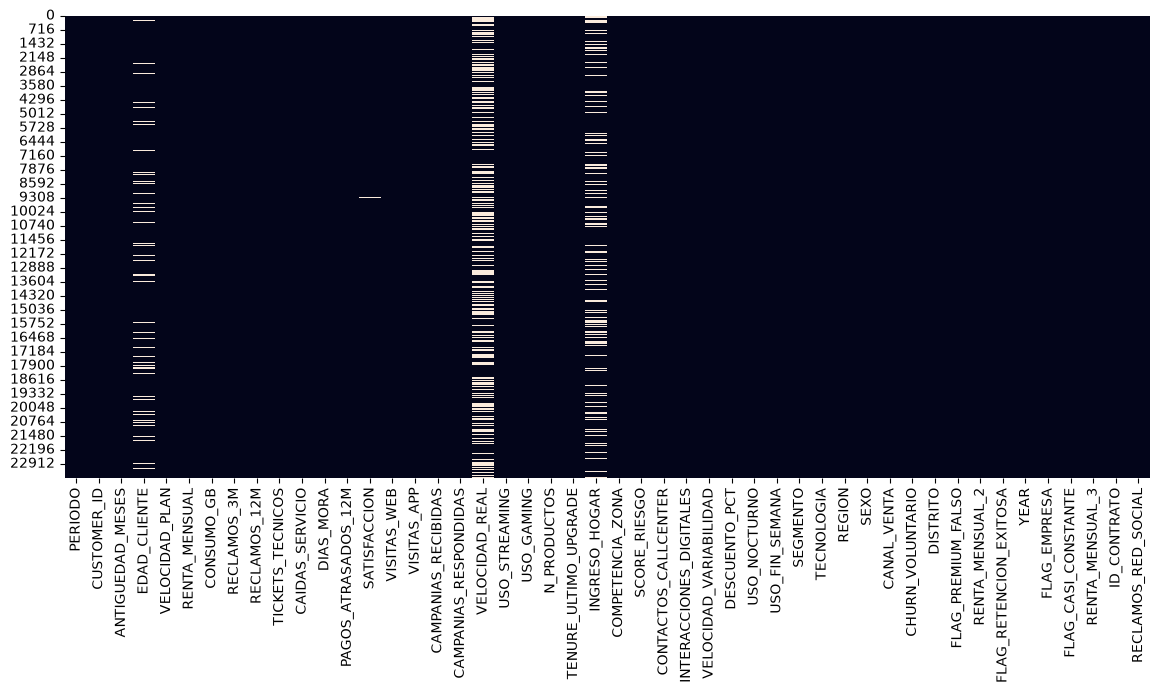

In [24]:
#Heatmap de nulos
plt.figure(figsize=(14,6))

sns.heatmap(
    df.isnull(),
    cbar=False
)

plt.show()

In [32]:
#Detección MCAR / MAR / MNAR
#Ejemplo para INGRESO_HOGAR.
missing_flag = (
    df["INGRESO_HOGAR"]
    .isnull()
    .astype(int)
)

In [33]:
#Cruzar contra variables.
for col in num_cols[:10]:

    corr = np.corrcoef(
        missing_flag,
        df[col].fillna(
            df[col].median()
        )
    )[0,1]

    print(
        col,
        round(corr,3)
    )

ANTIGUEDAD_MESES 0.007
EDAD_CLIENTE -0.018
VELOCIDAD_PLAN -0.002
RENTA_MENSUAL -0.003
CONSUMO_GB 0.007
RECLAMOS_3M 0.002
RECLAMOS_12M 0.005
TICKETS_TECNICOS -0.004
CAIDAS_SERVICIO 0.004
DIAS_MORA 0.006


## Creación de ventanas

In [34]:
df1 = pd.read_csv(path_data_raw + "/dataset_churn_ventanas.csv")

In [35]:
# A esto se le llama ABT 
# siempre se hace preprocesamiento de datos en el train para evitar OVERFITTING
df1.head(5)

,CUSTOMER_ID,VENTANA,TARGET_CHURN,ANTIGUEDAD_MESES,EDAD_CLIENTE,VELOCIDAD_PLAN,RENTA_MENSUAL_6M,CONSUMO_GB_6M,RECLAMOS_3M_6M,RECLAMOS_12M_6M,TICKETS_TECNICOS_6M,CAIDAS_SERVICIO_6M,DIAS_MORA_6M,PAGOS_ATRASADOS_12M_6M,SATISFACCION_6M,VISITAS_WEB_6M,VISITAS_APP_6M,CAMPANIAS_RECIBIDAS_6M,CAMPANIAS_RESPONDIDAS_6M,VELOCIDAD_REAL_6M,USO_STREAMING_6M,USO_GAMING_6M,N_PRODUCTOS_6M,TENURE_ULTIMO_UPGRADE_6M,INGRESO_HOGAR_6M,COMPETENCIA_ZONA_6M,SCORE_RIESGO_6M,CONTACTOS_CALLCENTER_6M,INTERACCIONES_DIGITALES_6M,VELOCIDAD_VARIABILIDAD_6M,DESCUENTO_PCT_6M,USO_NOCTURNO_6M,USO_FIN_SEMANA_6M,FLAG_PREMIUM_FALSO_6M,RENTA_MENSUAL_2_6M,FLAG_EMPRESA_6M,FLAG_CASI_CONSTANTE_6M,RENTA_MENSUAL_3_6M,RECLAMOS_RED_SOCIAL_6M,INTERACCIONES_DIGITALES_SUM_6M,RECLAMOS_RED_SOCIAL_SUM_6M,DIAS_MORA_SUM_6M,RECLAMOS_3M_SUM_6M,CAMPANIAS_RESPONDIDAS_SUM_6M,CONTACTOS_CALLCENTER_SUM_6M,N_PRODUCTOS_SUM_6M,VISITAS_APP_SUM_6M,VISITAS_WEB_SUM_6M,PAGOS_ATRASADOS_12M_SUM_6M,CAMPANIAS_RECIBIDAS_SUM_6M,RECLAMOS_12M_SUM_6M,TICKETS_TECNICOS_SUM_6M,CAIDAS_SERVICIO_SUM_6M,RENTA_MENSUAL_3M,CONSUMO_GB_3M,RECLAMOS_3M_3M,RECLAMOS_12M_3M,TICKETS_TECNICOS_3M,CAIDAS_SERVICIO_3M,DIAS_MORA_3M,PAGOS_ATRASADOS_12M_3M,SATISFACCION_3M,VISITAS_WEB_3M,VISITAS_APP_3M,CAMPANIAS_RECIBIDAS_3M,CAMPANIAS_RESPONDIDAS_3M,VELOCIDAD_REAL_3M,USO_STREAMING_3M,USO_GAMING_3M,N_PRODUCTOS_3M,TENURE_ULTIMO_UPGRADE_3M,INGRESO_HOGAR_3M,COMPETENCIA_ZONA_3M,SCORE_RIESGO_3M,CONTACTOS_CALLCENTER_3M,INTERACCIONES_DIGITALES_3M,VELOCIDAD_VARIABILIDAD_3M,DESCUENTO_PCT_3M,USO_NOCTURNO_3M,USO_FIN_SEMANA_3M,FLAG_PREMIUM_FALSO_3M,RENTA_MENSUAL_2_3M,FLAG_EMPRESA_3M,FLAG_CASI_CONSTANTE_3M,RENTA_MENSUAL_3_3M,RECLAMOS_RED_SOCIAL_3M,INTERACCIONES_DIGITALES_SUM_3M,RECLAMOS_RED_SOCIAL_SUM_3M,DIAS_MORA_SUM_3M,RECLAMOS_3M_SUM_3M,CAMPANIAS_RESPONDIDAS_SUM_3M,CONTACTOS_CALLCENTER_SUM_3M,N_PRODUCTOS_SUM_3M,VISITAS_APP_SUM_3M,VISITAS_WEB_SUM_3M,PAGOS_ATRASADOS_12M_SUM_3M,CAMPANIAS_RECIBIDAS_SUM_3M,RECLAMOS_12M_SUM_3M,TICKETS_TECNICOS_SUM_3M,CAIDAS_SERVICIO_SUM_3M,RENTA_MENSUAL_UM,CONSUMO_GB_UM,RECLAMOS_3M_UM,RECLAMOS_12M_UM,TICKETS_TECNICOS_UM,CAIDAS_SERVICIO_UM,DIAS_MORA_UM,PAGOS_ATRASADOS_12M_UM,SATISFACCION_UM,VISITAS_WEB_UM,VISITAS_APP_UM,CAMPANIAS_RECIBIDAS_UM,CAMPANIAS_RESPONDIDAS_UM,VELOCIDAD_REAL_UM,USO_STREAMING_UM,USO_GAMING_UM,N_PRODUCTOS_UM,TENURE_ULTIMO_UPGRADE_UM,INGRESO_HOGAR_UM,COMPETENCIA_ZONA_UM,SCORE_RIESGO_UM,CONTACTOS_CALLCENTER_UM,INTERACCIONES_DIGITALES_UM,VELOCIDAD_VARIABILIDAD_UM,DESCUENTO_PCT_UM,USO_NOCTURNO_UM,USO_FIN_SEMANA_UM,FLAG_PREMIUM_FALSO_UM,RENTA_MENSUAL_2_UM,FLAG_EMPRESA_UM,FLAG_CASI_CONSTANTE_UM,RENTA_MENSUAL_3_UM,RECLAMOS_RED_SOCIAL_UM,SEGMENTO_MODE_6M,SEGMENTO_MODE_3M,SEGMENTO_UM,TECNOLOGIA_MODE_6M,TECNOLOGIA_MODE_3M,TECNOLOGIA_UM,REGION_MODE_6M,REGION_MODE_3M,REGION_UM,SEXO_MODE_6M,SEXO_MODE_3M,SEXO_UM,CANAL_VENTA_MODE_6M,CANAL_VENTA_MODE_3M,CANAL_VENTA_UM,DISTRITO_MODE_6M,DISTRITO_MODE_3M,DISTRITO_UM,PERIODO_INICIO_PRED,PERIODO_FIN_PRED_EXCL,PERIODO_TARGET
0,CUST_000001,VENTANA1,0,129.0,72.0,50.0,6.479856,384.699198,0.833333,3.333333,1.166667,1.666667,1.833333,1.833333,8.710954,15.000000,13.500000,3.166667,1.833333,45.068107,37.833333,52.500000,2.0,20.666667,3691.652991,2.0,0.607967,1.000000,9.666667,11.139647,25.245184,57.613889,52.874262,1.0,5.711413,1.0,1.0,6.840057,0.709838,58.0,4.259030,11.0,5.0,11.0,6.0,12.0,81.0,90.0,11.0,19.0,20.0,7.0,10.0,6.715143,389.947847,1.000000,3.333333,1.000000,2.000000,1.333333,2.333333,8.198737,16.000000,14.333333,2.666667,2.666667,43.446478,50.000000,31.666667,2.0,29.000000,3893.858731,2.0,0.795065,0.666667,7.666667,15.601024,24.523643,29.979000,40.526860,1.0,5.910491,1.0,1.0,6.552893,1.049271,23.0,3.147813,4.0,3.0,8.0,2.0,6.0,43.0,48.0,7.0,8.0,10.0,3.0,6.0,9.463746,378.551997,2.0,5.0,1.0,2.0,3.0,4.0,8.234211,14.0,19.0,4.0,4.0,44.178550,43.0,21.0,2.0,30.0,NaN,2.0,0.854268,0.0,10.0,25.043955,30.472210,32.909588,53.395655,1.0,7.537784,1.0,1.0,10.661309,1.180396,Masivo,Masivo,Masivo,Fibra,Fibra,Fibra,Lima,Lima,Lima,M,M,M,Call Center,Call Center,Call Center,DIST_124,DI

In [36]:
num_cols = df1.select_dtypes(include=np.number).columns.tolist()

cat_cols = df1.select_dtypes(include=["object","category"]).columns.tolist()

# excluir target y id

num_cols = [c for c in num_cols if c != TARGET]

cat_cols = [c for c in cat_cols if c != ID_COL]

In [39]:
len(num_cols)

131

In [40]:
len(cat_cols)

22

### Análisis de Nulos

In [37]:
#2. Análisis de nulos
nulos = pd.DataFrame({
    "feature":df1.columns,
    "nulos": df1.isnull().sum(),
    "pct_nulos":round(df1.isnull().mean(),2)})
nulos.sort_values("pct_nulos",ascending=False)


,feature,nulos,pct_nulos
VELOCIDAD_REAL_UM,VELOCIDAD_REAL_UM,1050,0.39
INGRESO_HOGAR_UM,INGRESO_HOGAR_UM,529,0.20
VELOCIDAD_REAL_3M,VELOCIDAD_REAL_3M,151,0.06
INGRESO_HOGAR_3M,INGRESO_HOGAR_3M,73,0.03
INGRESO_HOGAR_6M,INGRESO_HOGAR_6M,37,0.01
VELOCIDAD_PLAN,VELOCIDAD_PLAN,0,0.00
TARGET_CHURN,TARGET_CHURN,0,0.00
ANTIGUEDAD_MESES,ANTIGUEDAD_MESES,0,0.00
EDAD_CLIENTE,EDAD_CLIENTE,0,0.00
CUSTOMER_ID,CUSTOMER_ID,0,0.00


In [44]:
from scipy.stats import mannwhitneyu, chi2_contingency
from statsmodels.stats.multitest import multipletests

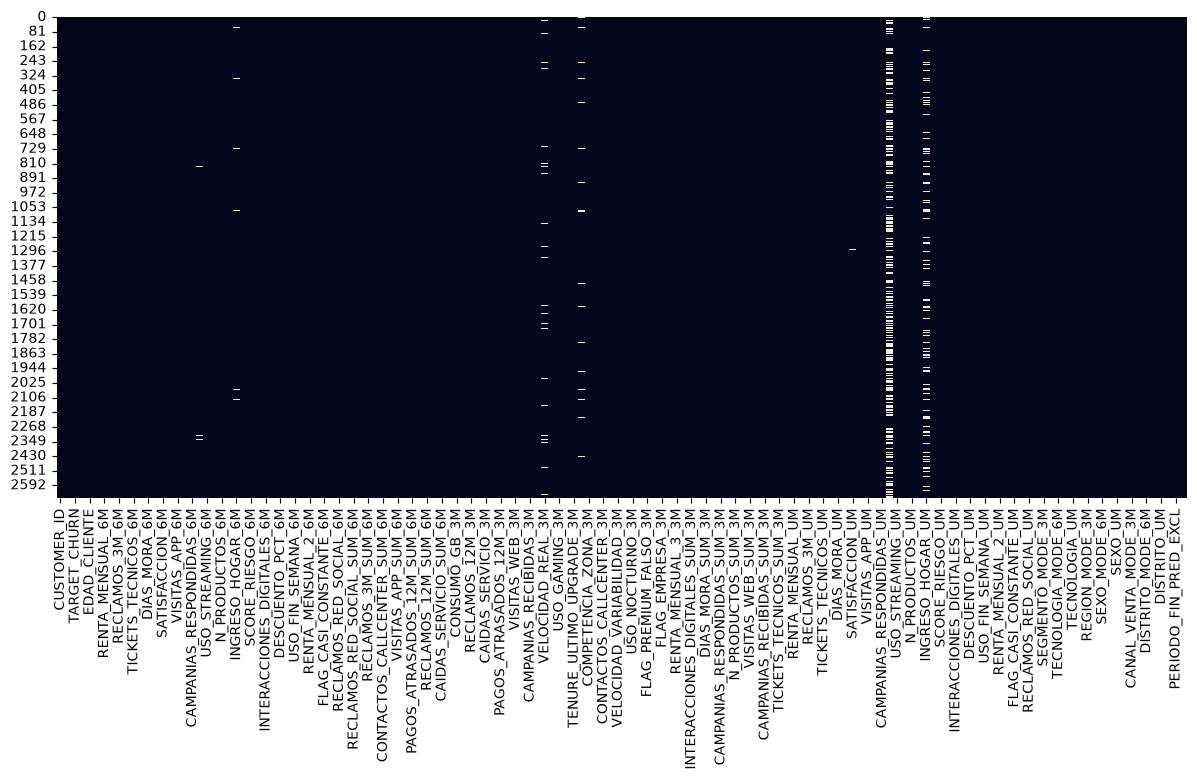

In [43]:
#Heatmap de nulos
plt.figure(figsize=(14,6))
sns.heatmap(df1.isnull(),cbar=False)
plt.show()

In [ ]:
#H0: Los datos faltan completamente al azar (MCAR)
#    las medias de cada variable NO cambian entre grupos con y sin NA 

#(H1): Los datos NO faltan al azar
#      las medias SÍ cambian según el patrón de NA

### Detección de anomalías

Diferencia entre outlier y una anomalía; el outlier se puede hallar con estadística. 
dato anómalo es un patrón (por eso se puede predecir); una anomalía puede ser un outlier, pero un outlier no puede ser una anomalía. 

Anomalía local y externa

* Local: Un dato que parece normal si miras todo el dataset, pero es raro comparado con sus vecinos más cercanos (un subgrupo o clúster específico).

* Externa o Exógena: Un dato que se aleja muchísimo de todo el conjunto de datos (no se hace con isolation forest, aquí ayuda el DBSCAN--> usualmente lo detecta como -1)

In [26]:
from prep_nulos import analizar_mecanismos_nulos

In [44]:
df_resumen, df_detalle = analizar_mecanismos_nulos(df1)


CLASE 24/11

## 1. Vamos a construir un dataset de modelamiento de churn con estas características:
1. Un registro único por CUSTOMER_ID y ventana temporal.
2. Variables numéricas agregadas mediante promedio, suma, máximo, mínimo y último valor.
3. Variables categóricas agregadas mediante moda y último valor.
4. Variables temporales de comportamiento: últimos 6 meses (6M), últimos 3 meses (3M) y último mes (UM).
5. El target se obtendrá exclusivamente del período siguiente a la ventana predictora.

In [50]:
df1 = pd.read_csv(path_data_raw + "/dataset_churn_ventanas.csv")

In [53]:
df1.head(5)

,CUSTOMER_ID,VENTANA,TARGET_CHURN,ANTIGUEDAD_MESES,EDAD_CLIENTE,VELOCIDAD_PLAN,RENTA_MENSUAL_6M,CONSUMO_GB_6M,RECLAMOS_3M_6M,RECLAMOS_12M_6M,TICKETS_TECNICOS_6M,CAIDAS_SERVICIO_6M,DIAS_MORA_6M,PAGOS_ATRASADOS_12M_6M,SATISFACCION_6M,VISITAS_WEB_6M,VISITAS_APP_6M,CAMPANIAS_RECIBIDAS_6M,CAMPANIAS_RESPONDIDAS_6M,VELOCIDAD_REAL_6M,USO_STREAMING_6M,USO_GAMING_6M,N_PRODUCTOS_6M,TENURE_ULTIMO_UPGRADE_6M,INGRESO_HOGAR_6M,COMPETENCIA_ZONA_6M,SCORE_RIESGO_6M,CONTACTOS_CALLCENTER_6M,INTERACCIONES_DIGITALES_6M,VELOCIDAD_VARIABILIDAD_6M,DESCUENTO_PCT_6M,USO_NOCTURNO_6M,USO_FIN_SEMANA_6M,FLAG_PREMIUM_FALSO_6M,RENTA_MENSUAL_2_6M,FLAG_EMPRESA_6M,FLAG_CASI_CONSTANTE_6M,RENTA_MENSUAL_3_6M,RECLAMOS_RED_SOCIAL_6M,INTERACCIONES_DIGITALES_SUM_6M,RECLAMOS_RED_SOCIAL_SUM_6M,DIAS_MORA_SUM_6M,RECLAMOS_3M_SUM_6M,CAMPANIAS_RESPONDIDAS_SUM_6M,CONTACTOS_CALLCENTER_SUM_6M,N_PRODUCTOS_SUM_6M,VISITAS_APP_SUM_6M,VISITAS_WEB_SUM_6M,PAGOS_ATRASADOS_12M_SUM_6M,CAMPANIAS_RECIBIDAS_SUM_6M,RECLAMOS_12M_SUM_6M,TICKETS_TECNICOS_SUM_6M,CAIDAS_SERVICIO_SUM_6M,RENTA_MENSUAL_3M,CONSUMO_GB_3M,RECLAMOS_3M_3M,RECLAMOS_12M_3M,TICKETS_TECNICOS_3M,CAIDAS_SERVICIO_3M,DIAS_MORA_3M,PAGOS_ATRASADOS_12M_3M,SATISFACCION_3M,VISITAS_WEB_3M,VISITAS_APP_3M,CAMPANIAS_RECIBIDAS_3M,CAMPANIAS_RESPONDIDAS_3M,VELOCIDAD_REAL_3M,USO_STREAMING_3M,USO_GAMING_3M,N_PRODUCTOS_3M,TENURE_ULTIMO_UPGRADE_3M,INGRESO_HOGAR_3M,COMPETENCIA_ZONA_3M,SCORE_RIESGO_3M,CONTACTOS_CALLCENTER_3M,INTERACCIONES_DIGITALES_3M,VELOCIDAD_VARIABILIDAD_3M,DESCUENTO_PCT_3M,USO_NOCTURNO_3M,USO_FIN_SEMANA_3M,FLAG_PREMIUM_FALSO_3M,RENTA_MENSUAL_2_3M,FLAG_EMPRESA_3M,FLAG_CASI_CONSTANTE_3M,RENTA_MENSUAL_3_3M,RECLAMOS_RED_SOCIAL_3M,INTERACCIONES_DIGITALES_SUM_3M,RECLAMOS_RED_SOCIAL_SUM_3M,DIAS_MORA_SUM_3M,RECLAMOS_3M_SUM_3M,CAMPANIAS_RESPONDIDAS_SUM_3M,CONTACTOS_CALLCENTER_SUM_3M,N_PRODUCTOS_SUM_3M,VISITAS_APP_SUM_3M,VISITAS_WEB_SUM_3M,PAGOS_ATRASADOS_12M_SUM_3M,CAMPANIAS_RECIBIDAS_SUM_3M,RECLAMOS_12M_SUM_3M,TICKETS_TECNICOS_SUM_3M,CAIDAS_SERVICIO_SUM_3M,RENTA_MENSUAL_UM,CONSUMO_GB_UM,RECLAMOS_3M_UM,RECLAMOS_12M_UM,TICKETS_TECNICOS_UM,CAIDAS_SERVICIO_UM,DIAS_MORA_UM,PAGOS_ATRASADOS_12M_UM,SATISFACCION_UM,VISITAS_WEB_UM,VISITAS_APP_UM,CAMPANIAS_RECIBIDAS_UM,CAMPANIAS_RESPONDIDAS_UM,VELOCIDAD_REAL_UM,USO_STREAMING_UM,USO_GAMING_UM,N_PRODUCTOS_UM,TENURE_ULTIMO_UPGRADE_UM,INGRESO_HOGAR_UM,COMPETENCIA_ZONA_UM,SCORE_RIESGO_UM,CONTACTOS_CALLCENTER_UM,INTERACCIONES_DIGITALES_UM,VELOCIDAD_VARIABILIDAD_UM,DESCUENTO_PCT_UM,USO_NOCTURNO_UM,USO_FIN_SEMANA_UM,FLAG_PREMIUM_FALSO_UM,RENTA_MENSUAL_2_UM,FLAG_EMPRESA_UM,FLAG_CASI_CONSTANTE_UM,RENTA_MENSUAL_3_UM,RECLAMOS_RED_SOCIAL_UM,SEGMENTO_MODE_6M,SEGMENTO_MODE_3M,SEGMENTO_UM,TECNOLOGIA_MODE_6M,TECNOLOGIA_MODE_3M,TECNOLOGIA_UM,REGION_MODE_6M,REGION_MODE_3M,REGION_UM,SEXO_MODE_6M,SEXO_MODE_3M,SEXO_UM,CANAL_VENTA_MODE_6M,CANAL_VENTA_MODE_3M,CANAL_VENTA_UM,DISTRITO_MODE_6M,DISTRITO_MODE_3M,DISTRITO_UM,PERIODO_INICIO_PRED,PERIODO_FIN_PRED_EXCL,PERIODO_TARGET
0,CUST_000001,VENTANA1,0,129.0,72.0,50.0,6.479856,384.699198,0.833333,3.333333,1.166667,1.666667,1.833333,1.833333,8.710954,15.000000,13.500000,3.166667,1.833333,45.068107,37.833333,52.500000,2.0,20.666667,3691.652991,2.0,0.607967,1.000000,9.666667,11.139647,25.245184,57.613889,52.874262,1.0,5.711413,1.0,1.0,6.840057,0.709838,58.0,4.259030,11.0,5.0,11.0,6.0,12.0,81.0,90.0,11.0,19.0,20.0,7.0,10.0,6.715143,389.947847,1.000000,3.333333,1.000000,2.000000,1.333333,2.333333,8.198737,16.000000,14.333333,2.666667,2.666667,43.446478,50.000000,31.666667,2.0,29.000000,3893.858731,2.0,0.795065,0.666667,7.666667,15.601024,24.523643,29.979000,40.526860,1.0,5.910491,1.0,1.0,6.552893,1.049271,23.0,3.147813,4.0,3.0,8.0,2.0,6.0,43.0,48.0,7.0,8.0,10.0,3.0,6.0,9.463746,378.551997,2.0,5.0,1.0,2.0,3.0,4.0,8.234211,14.0,19.0,4.0,4.0,44.178550,43.0,21.0,2.0,30.0,NaN,2.0,0.854268,0.0,10.0,25.043955,30.472210,32.909588,53.395655,1.0,7.537784,1.0,1.0,10.661309,1.180396,Masivo,Masivo,Masivo,Fibra,Fibra,Fibra,Lima,Lima,Lima,M,M,M,Call Center,Call Center,Call Center,DIST_124,DI

In [54]:
df1['VENTANA'].value_counts()

VENTANA
VENTANA1    896
VENTANA2    885
VENTANA3    883
Name: count, dtype: int64

### usaremos: 
* w1 para entrenar
* w2 para testear
* w3 como ott

In [55]:
# Filtrar el dataframe para incluir solo la ventana 1
df=df1[df1['VENTANA']=='VENTANA1']

In [ ]:
TARGET = "TARGET_CHURN"
ID_COL = "CUSTOMER_ID"
num_cols = df.select_dtypes(include=np.number).columns.tolist()

cat_cols = df.select_dtypes(include=["object","category"]).columns.tolist()

# excluir target y id

num_cols = [c for c in num_cols if c != TARGET]
cat_cols = [c for c in cat_cols if c != ID_COL]

In [57]:
#1. Cantidad de variables y filas
print("Filas :", len(df))
print("Columnas :", len(df.columns))

print("\nVariables Numéricas")
print(len(num_cols))

print("\nVariables Categóricas")
print(len(cat_cols))

Filas : 896
Columnas : 154

Variables Numéricas
130

Variables Categóricas
22


In [58]:
#2. Análisis de nulos
nulos = pd.DataFrame({
    "feature":df.columns,
    "nulos":df.isnull().sum(),
    "pct_nulos":round(100*df.isnull().mean(),2)})
nulos.sort_values("pct_nulos",ascending=False)

,feature,nulos,pct_nulos
VELOCIDAD_REAL_UM,VELOCIDAD_REAL_UM,354,39.51
INGRESO_HOGAR_UM,INGRESO_HOGAR_UM,175,19.53
VELOCIDAD_REAL_3M,VELOCIDAD_REAL_3M,44,4.91
INGRESO_HOGAR_3M,INGRESO_HOGAR_3M,23,2.57
INGRESO_HOGAR_6M,INGRESO_HOGAR_6M,11,1.23
SATISFACCION_UM,SATISFACCION_UM,2,0.22
VELOCIDAD_REAL_6M,VELOCIDAD_REAL_6M,2,0.22
TARGET_CHURN,TARGET_CHURN,0,0.00
EDAD_CLIENTE,EDAD_CLIENTE,0,0.00
ANTIGUEDAD_MESES,ANTIGUEDAD_MESES,0,0.00


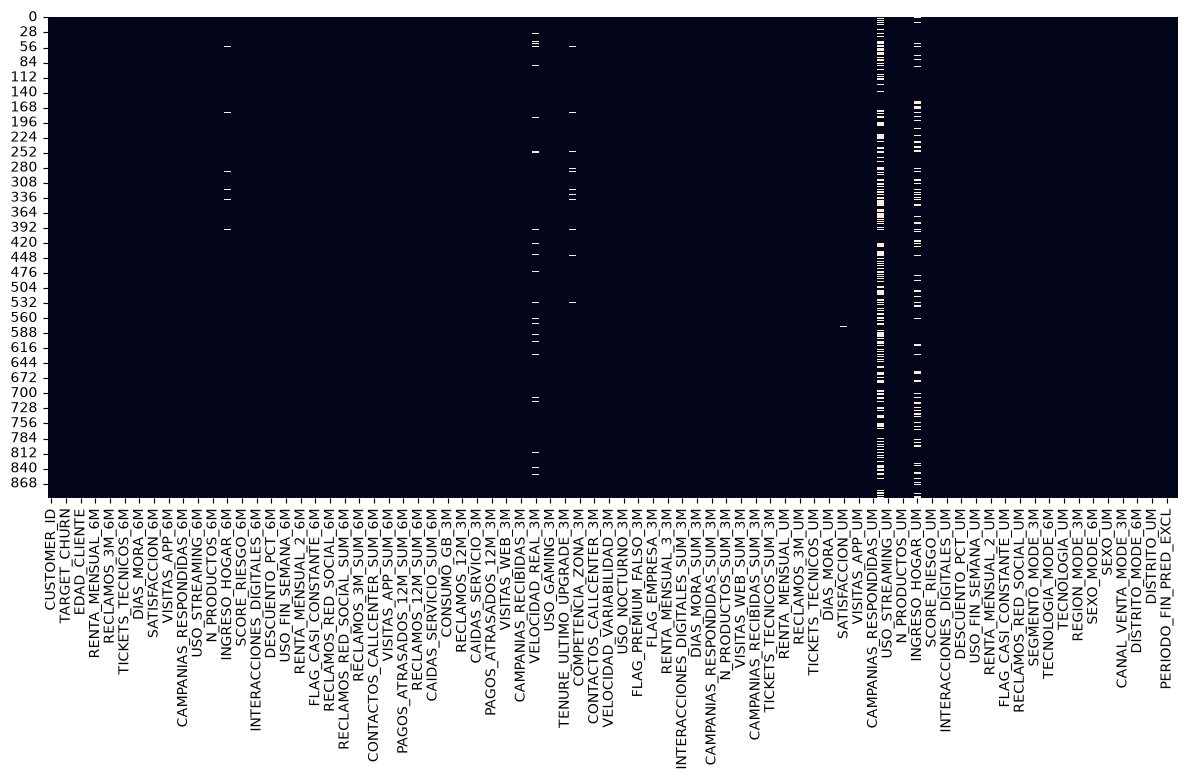

In [ ]:
#Heatmap de nulos
plt.figure(figsize=(14,6))
sns.heatmap(df.isnull(),cbar=False)
plt.show()

### Analizar Nulos segun su mecanismo (MCAR, MAR,MNAR)

In [60]:
from prep_nulos import analizar_mecanismos_nulos

In [61]:
df_resumen, df_detalle = analizar_mecanismos_nulos(df1)
display(df_resumen)

,variable,nulos,porcentaje_nulos,variables_evaluadas,asociaciones_significativas,diagnostico
0,VELOCIDAD_REAL_6M,8,0.30,0,0,Sin evidencia contra MCAR - no concluyente
1,INGRESO_HOGAR_6M,37,1.39,148,12,MCAR rechazada - compatible con MAR
2,VELOCIDAD_REAL_3M,151,5.67,149,2,MCAR rechazada - compatible con MAR
3,INGRESO_HOGAR_3M,73,2.74,149,13,MCAR rechazada - compatible con MAR
4,SATISFACCION_UM,6,0.23,0,0,Sin evidencia contra MCAR - no concluyente
5,VELOCIDAD_REAL_UM,1050,39.41,150,0,Sin evidencia contra MCAR - no concluyente
6,INGRESO_HOGAR_UM,529,19.86,150,4,MCAR rechazada - compatible con MAR


Los nulos con MNAR es difícil imputar, porque el valor depende de esa misma variable

### tratamiento de nulos

### Estrategia recomendada por variable

Priorizando conservación de información y desempeño predictivo para tu modelo de churn.


![](../img/img1.png)

In [63]:
# cuando tenemos nulos creamos una variable indicadora para conservar el patrón de los nulos 

## deteccion de anomalias

es importante es entender que cada técnica observa los datos desde una perspectiva diferente:
- IQR: detecta valores extremos comparándolos con los cuartiles.
- MAD: detecta valores alejados de la mediana utilizando una medida robusta de dispersión.
- Isolation Forest: detecta registros que presentan combinaciones inusuales de variables.

El resultado final no es solamente identificar qué valores son extraños, sino también identificar qué clientes presentan comportamientos atípicos.

In [64]:
from prep_anomalias import detectar_anomalias

Usualmente no podemos detectar el valor anómalo, lo que se hace es hacer un modelo, puede ser el **isolation forest**, ello nos ayuda a poder saber el comportamiento del dato anómalo haciendo splits

In [65]:
resumen_anomalias, df_anomalias, df_scoring, resumen_infinitos = (
    detectar_anomalias(df,contamination=0.02,excluir=["CUSTOMER_ID"]))

In [66]:
#visualizar
display(resumen_anomalias)

print("Registros anómalos:", len(df_anomalias))

display(df_anomalias.head(20))

print("Valores infinitos:")
display(resumen_infinitos[resumen_infinitos > 0])

,variable,n_validos,n_nulos,mediana,Q1,Q3,limite_inferior,limite_superior,outliers_IQR,porcentaje_IQR,outliers_MAD,porcentaje_MAD
71,VISITAS_APP_UM,896,0,11.000000,9.000000,14.000000,1.500000e+00,21.500000,53,5.92,0,0.00
43,VISITAS_APP_3M,896,0,11.666667,10.333333,13.333333,5.833333e+00,17.833333,52,5.80,48,5.36
61,VISITAS_APP_SUM_3M,896,0,35.000000,31.000000,40.000000,1.750000e+01,53.500000,52,5.80,48,5.36
11,VISITAS_APP_6M,896,0,11.833333,10.833333,12.833333,7.833333e+00,15.833333,51,5.69,47,5.25
81,RENTA_MENSUAL_2_UM,896,0,31.387003,15.734598,50.625956,-3.660244e+01,102.962993,51,5.69,43,4.80
66,RENTA_MENSUAL_UM,896,0,30.433486,14.951857,49.795195,-3.731315e+01,102.060204,51,5.69,43,4.80
30,VISITAS_APP_SUM_6M,896,0,71.000000,65.000000,77.000000,4.700000e+01,95.000000,50,5.58,47,5.25
82,RENTA_MENSUAL_3_UM,896,0,29.529122,14.446010,48.915839,-3.725873e+01,100.620582,50,5.58,43,4.80
13,USO_GAMING_6M,896,0,48.333333,40.500000,56.666667,1.625000e+01,80.916667,49,5.47,47,5.25
3,CONSUMO_GB_6M,896,0,268.489849,203.760811,352.044389,-1.866456e+01,574.469755,47,5.25,41,4.58


Registros anómalos: 342


,CUSTOMER_ID,VENTANA,TARGET_CHURN,ANTIGUEDAD_MESES,EDAD_CLIENTE,VELOCIDAD_PLAN,RENTA_MENSUAL_6M,CONSUMO_GB_6M,RECLAMOS_3M_6M,RECLAMOS_12M_6M,TICKETS_TECNICOS_6M,CAIDAS_SERVICIO_6M,DIAS_MORA_6M,PAGOS_ATRASADOS_12M_6M,SATISFACCION_6M,VISITAS_WEB_6M,VISITAS_APP_6M,CAMPANIAS_RECIBIDAS_6M,CAMPANIAS_RESPONDIDAS_6M,VELOCIDAD_REAL_6M,USO_STREAMING_6M,USO_GAMING_6M,N_PRODUCTOS_6M,TENURE_ULTIMO_UPGRADE_6M,INGRESO_HOGAR_6M,COMPETENCIA_ZONA_6M,SCORE_RIESGO_6M,CONTACTOS_CALLCENTER_6M,INTERACCIONES_DIGITALES_6M,VELOCIDAD_VARIABILIDAD_6M,DESCUENTO_PCT_6M,USO_NOCTURNO_6M,USO_FIN_SEMANA_6M,FLAG_PREMIUM_FALSO_6M,RENTA_MENSUAL_2_6M,FLAG_EMPRESA_6M,FLAG_CASI_CONSTANTE_6M,RENTA_MENSUAL_3_6M,RECLAMOS_RED_SOCIAL_6M,INTERACCIONES_DIGITALES_SUM_6M,RECLAMOS_RED_SOCIAL_SUM_6M,DIAS_MORA_SUM_6M,RECLAMOS_3M_SUM_6M,CAMPANIAS_RESPONDIDAS_SUM_6M,CONTACTOS_CALLCENTER_SUM_6M,N_PRODUCTOS_SUM_6M,VISITAS_APP_SUM_6M,VISITAS_WEB_SUM_6M,PAGOS_ATRASADOS_12M_SUM_6M,CAMPANIAS_RECIBIDAS_SUM_6M,RECLAMOS_12M_SUM_6M,TICKETS_TECNICOS_SUM_6M,CAIDAS_SERVICIO_SUM_6M,RENTA_MENSUAL_3M,CONSUMO_GB_3M,RECLAMOS_3M_3M,RECLAMOS_12M_3M,TICKETS_TECNICOS_3M,CAIDAS_SERVICIO_3M,DIAS_MORA_3M,PAGOS_ATRASADOS_12M_3M,SATISFACCION_3M,VISITAS_WEB_3M,VISITAS_APP_3M,CAMPANIAS_RECIBIDAS_3M,CAMPANIAS_RESPONDIDAS_3M,VELOCIDAD_REAL_3M,USO_STREAMING_3M,USO_GAMING_3M,N_PRODUCTOS_3M,TENURE_ULTIMO_UPGRADE_3M,INGRESO_HOGAR_3M,COMPETENCIA_ZONA_3M,SCORE_RIESGO_3M,CONTACTOS_CALLCENTER_3M,INTERACCIONES_DIGITALES_3M,VELOCIDAD_VARIABILIDAD_3M,DESCUENTO_PCT_3M,USO_NOCTURNO_3M,USO_FIN_SEMANA_3M,FLAG_PREMIUM_FALSO_3M,RENTA_MENSUAL_2_3M,FLAG_EMPRESA_3M,FLAG_CASI_CONSTANTE_3M,RENTA_MENSUAL_3_3M,RECLAMOS_RED_SOCIAL_3M,INTERACCIONES_DIGITALES_SUM_3M,RECLAMOS_RED_SOCIAL_SUM_3M,DIAS_MORA_SUM_3M,RECLAMOS_3M_SUM_3M,CAMPANIAS_RESPONDIDAS_SUM_3M,CONTACTOS_CALLCENTER_SUM_3M,N_PRODUCTOS_SUM_3M,VISITAS_APP_SUM_3M,VISITAS_WEB_SUM_3M,PAGOS_ATRASADOS_12M_SUM_3M,CAMPANIAS_RECIBIDAS_SUM_3M,RECLAMOS_12M_SUM_3M,TICKETS_TECNICOS_SUM_3M,CAIDAS_SERVICIO_SUM_3M,RENTA_MENSUAL_UM,CONSUMO_GB_UM,RECLAMOS_3M_UM,RECLAMOS_12M_UM,TICKETS_TECNICOS_UM,CAIDAS_SERVICIO_UM,DIAS_MORA_UM,PAGOS_ATRASADOS_12M_UM,SATISFACCION_UM,VISITAS_WEB_UM,VISITAS_APP_UM,CAMPANIAS_RECIBIDAS_UM,CAMPANIAS_RESPONDIDAS_UM,VELOCIDAD_REAL_UM,USO_STREAMING_UM,USO_GAMING_UM,N_PRODUCTOS_UM,TENURE_ULTIMO_UPGRADE_UM,INGRESO_HOGAR_UM,COMPETENCIA_ZONA_UM,SCORE_RIESGO_UM,CONTACTOS_CALLCENTER_UM,INTERACCIONES_DIGITALES_UM,VELOCIDAD_VARIABILIDAD_UM,DESCUENTO_PCT_UM,USO_NOCTURNO_UM,USO_FIN_SEMANA_UM,FLAG_PREMIUM_FALSO_UM,RENTA_MENSUAL_2_UM,FLAG_EMPRESA_UM,FLAG_CASI_CONSTANTE_UM,RENTA_MENSUAL_3_UM,RECLAMOS_RED_SOCIAL_UM,SEGMENTO_MODE_6M,SEGMENTO_MODE_3M,SEGMENTO_UM,TECNOLOGIA_MODE_6M,TECNOLOGIA_MODE_3M,TECNOLOGIA_UM,REGION_MODE_6M,REGION_MODE_3M,REGION_UM,SEXO_MODE_6M,SEXO_MODE_3M,SEXO_UM,CANAL_VENTA_MODE_6M,CANAL_VENTA_MODE_3M,CANAL_VENTA_UM,DISTRITO_MODE_6M,DISTRITO_MODE_3M,DISTRITO_UM,PERIODO_INICIO_PRED,PERIODO_FIN_PRED_EXCL,PERIODO_TARGET,ANTIGUEDAD_MESES_IQR,ANTIGUEDAD_MESES_MAD,EDAD_CLIENTE_IQR,EDAD_CLIENTE_MAD,RENTA_MENSUAL_6M_IQR,RENTA_MENSUAL_6M_MAD,CONSUMO_GB_6M_IQR,CONSUMO_GB_6M_MAD,RECLAMOS_3M_6M_IQR,RECLAMOS_3M_6M_MAD,RECLAMOS_12M_6M_IQR,RECLAMOS_12M_6M_MAD,TICKETS_TECNICOS_6M_IQR,TICKETS_TECNICOS_6M_MAD,DIAS_MORA_6M_IQR,DIAS_MORA_6M_MAD,PAGOS_ATRASADOS_12M_6M_IQR,PAGOS_ATRASADOS_12M_6M_MAD,SATISFACCION_6M_IQR,SATISFACCION_6M_MAD,VISITAS_WEB_6M_IQR,VISITAS_WEB_6M_MAD,VISITAS_APP_6M_IQR,VISITAS_APP_6M_MAD,USO_STREAMING_6M_IQR,USO_STREAMING_6M_MAD,USO_GAMING_6M_IQR,USO_GAMING_6M_MAD,TENURE_ULTIMO_UPGRADE_6M_IQR,TENURE_ULTIMO_UPGRADE_6M_MAD,INGRESO_HOGAR_6M_IQR,INGRESO_HOGAR_6M_MAD,SCORE_RIESGO_6M_IQR,SCORE_RIESGO_6M_MAD,CONTACTOS_CALLCENTER_6M_IQR,CONTACTOS_CALLCENTER_6M_MAD,INTERACCIONES_DIGITALES_6M_IQR,INTERACCIONES_DIGITALES_6M_MAD,DESCUENTO_PCT_6M_IQR,DESCUENTO_PCT_6M_MAD,USO_NOCTURNO_6M_IQR,USO_NOCTURNO_6M_MAD,USO_FIN_SEMANA_6M_IQR,USO_FIN_SEMANA_6M_MAD,RENTA_MENSUAL_2_6M_IQR,RENTA_MENSUAL_2_6M_MAD,RENTA_MENSUAL_3_6M_IQR,RENTA_MENSUAL_3_6M_MAD,RECLAMOS_RED_SOCIAL_6M_IQR

Valores infinitos:


Series([], Name: valores_infinitos, dtype: int64)

**Lo usaría luego de hacer mi primer modelo beta, el estándar con ganas de mejorar el modelo, aplico lo que encontré**

### ¿Cómo utilizaría estas anomalías en el proyecto de churn?

No utilizaría el resultado para eliminar automáticamente clientes. Lo utilizaría para entender comportamientos atípicos y mejorar la calidad del modelo.

In [71]:
# Preguntar sobre como usaria el dato anómalo y su parámetro 

# variacion del modelo si le quito los datos anómalos y si le mantengo.

# parámetro = contaminación; suele asumir un número pequeño de datos anómalos para que haya un resultado apegado a la realidad


## Asimetría

Es peligroso

Los boosting, por detrás tiene su función de costo y ganancia, el algoritmo como LightGBM puede mandar variables arriba como muy importantes, por tener cachitos; el LIGHGBM lo manda al top1, el comportamiento es muy volátil en los tiempos T + n, usamos winsorización al 90%. Una forma de verlo es también ver que esa variable tiene una importancia alta usualmente > 50% de ganancia


![](../img/img2.jpg)


In [67]:
# Asimetría
def data_asimetria(df):
    def classificar_asimetria(valor_skew,umbral=1):
        if valor_skew > umbral:
            return " Asimetria positiva extrema"
        elif valor_skew <-umbral:
            return "Asimetria negativa extrema"
        else:
            return " Tiende Simetrica"
       
    resultados=[]
    for col in df.select_dtypes(include=[np.number]).columns:
        skew_val=df[col].skew()
        clasificacion=classificar_asimetria(skew_val,umbral=1)
        resultados.append([col,skew_val,clasificacion])
       
    #df final
    df_asimetria=pd.DataFrame(resultados,columns=['Variable','Skewness','Clasificacion'])
   
    return df_asimetria

In [68]:
df_asimetria=data_asimetria(df)

In [69]:
df_asimetria

,Variable,Skewness,Clasificacion
0,TARGET_CHURN,2.226014,Asimetria positiva extrema
1,ANTIGUEDAD_MESES,-0.022837,Tiende Simetrica
2,EDAD_CLIENTE,0.454836,Tiende Simetrica
3,VELOCIDAD_PLAN,2.215907,Asimetria positiva extrema
4,RENTA_MENSUAL_6M,2.222741,Asimetria positiva extrema
5,CONSUMO_GB_6M,3.706238,Asimetria positiva extrema
6,RECLAMOS_3M_6M,0.555876,Tiende Simetrica
7,RECLAMOS_12M_6M,0.276237,Tiende Simetrica
8,TICKETS_TECNICOS_6M,0.268384,Tiende Simetrica
9,CAIDAS_SERVICIO_6M,0.432751,Tiende Simetrica


Lo que se suele hacer es tenerlo identificado, lo que se hace es filtrar los asimétricos extremos, y se le aplica la winsorización con P99 y P1 y ayuda que el modelo sea más estable. Se hace un modelo beta como está para tener un punto de partida

## correlaciones

In [74]:
def correlaciones_fuertes(df, metodo="spearman", umbral=0.7):
    corr = df.select_dtypes(include=[np.number]).corr(method=metodo)
    corrs = (corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().reset_index())
    corrs.columns = ["Variable_1", "Variable_2", "Correlacion_abs"]
    return corrs[corrs["Correlacion_abs"] >= umbral].sort_values("Correlacion_abs", ascending=False)

In [75]:
cf=correlaciones_fuertes(df, metodo="spearman", umbral=0.7)
cf

,Variable_1,Variable_2,Correlacion_abs
7030,RECLAMOS_3M_3M,RECLAMOS_3M_SUM_3M,1.000000
7169,RECLAMOS_12M_3M,RECLAMOS_12M_SUM_3M,1.000000
9287,COMPETENCIA_ZONA_3M,COMPETENCIA_ZONA_UM,1.000000
9647,INTERACCIONES_DIGITALES_3M,INTERACCIONES_DIGITALES_SUM_3M,1.000000
8341,CAMPANIAS_RESPONDIDAS_3M,CAMPANIAS_RESPONDIDAS_SUM_3M,1.000000
3130,COMPETENCIA_ZONA_6M,COMPETENCIA_ZONA_UM,1.000000
3083,COMPETENCIA_ZONA_6M,COMPETENCIA_ZONA_3M,1.000000
2687,N_PRODUCTOS_6M,N_PRODUCTOS_3M,1.000000
2663,N_PRODUCTOS_6M,N_PRODUCTOS_SUM_6M,1.000000
2734,N_PRODUCTOS_6M,N_PRODUCTOS_UM,1.000000


Cuando hay alta correlación entre ellas hay multicolinealidad, eso se usa porque a los árboles no le afecta mucho; pero sí impacta al feature importance; muestra confianza al usuario para que pueda realizar sus campañas conociendo esas variables que le dan seguridad, se suele dejar la variable más correlacionada con la target

## Optimal bining

In [77]:
# !pip install optbinning

In [78]:
from optbinning import OptimalBinning
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [81]:
x = df["RECLAMOS_3M_6M"].values
y = df["TARGET_CHURN"].values

optb = OptimalBinning(
    name="RECLAMOS_3M",
    dtype="numerical",
    max_n_bins=5,
    min_bin_size=0.05, # cada variable tener un mínimo de 5% de total de observaciones
    monotonic_trend="auto")

optb.fit(x, y)

,name,'RECLAMOS_3M'
,max_n_bins,5
,min_bin_size,0.05
,dtype,'numerical'
,prebinning_method,'cart'
,solver,'cp'
,divergence,'iv'
,max_n_prebins,20
,min_prebin_size,0.05
,min_n_bins,None
,max_bin_size,None


### ¿Qué está haciendo cada parámetro?

* Parámetro:	Interpretación

* name:	Nombre de la variable

* dtype:	Variable numérica

* max_n_bins=5	: Máximo de cinco intervalos

* min_bin_size=0.05 :	Cada intervalo debe tener al menos 5% de observaciones

* monotonic_trend	: Busca una tendencia monotónica cuando corresponde

### ¿Qué significa optimización?

**OptBinning** busca puntos de corte que permitan diferenciar los clientes que abandonan de los que permanecen, considerando las restricciones configuradas.

In [82]:
binning_table = optb.binning_table
tabla = binning_table.build()
display(tabla)

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.75)",435,0.485491,381,54,0.124138,0.038172,0.000697,0.000087
1,"[0.75, 0.92)",172,0.191964,144,28,0.162791,-0.278034,0.016432,0.002047
2,"[0.92, 1.25)",201,0.224330,173,28,0.139303,-0.094556,0.002077,0.000260
3,"[1.25, inf)",88,0.098214,83,5,0.056818,0.89376,0.056124,0.006791
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,896,1.000000,781,115,0.128348,,0.075331,0.009185


### ¿Cómo interpretar cada columna?
Columna	:Significado

Bin:	Intervalo encontrado

Count	:Cantidad de clientes

Count (%)	:Participación de clientes

Non-event	:Clientes sin churn

Event	:Clientes con churn

Event rate:	Porcentaje de churn

WoE	:Evidencia a favor de una clase frente a otra

IV	:Capacidad de separación de la variable

JS	: Divergencia entre las distribuciones (Vemos que tanto se parecen las distribuciones)

Mutual informatión detecta relación no lineal de mi evento de interés con una variable explicativa; algo que el coeficiente de correlación no detecta. 

Lo que hago es el VI tener esto como referencia

Una referencia orientativa para interpretar IV:

IV	Interpretación habitual

* Menor a 0.02	Muy bajo
* 0.02–0.10	Bajo
* 0.10–0.30	Medio
* 0.30–0.50	Alto
* Mayor a 0.50	Revisar posible separación excesiva

### Generar los gráficos
Una de las ventajas de OptBinning es que los gráficos vienen integrados.

Gráfico 1: tasa de eventos

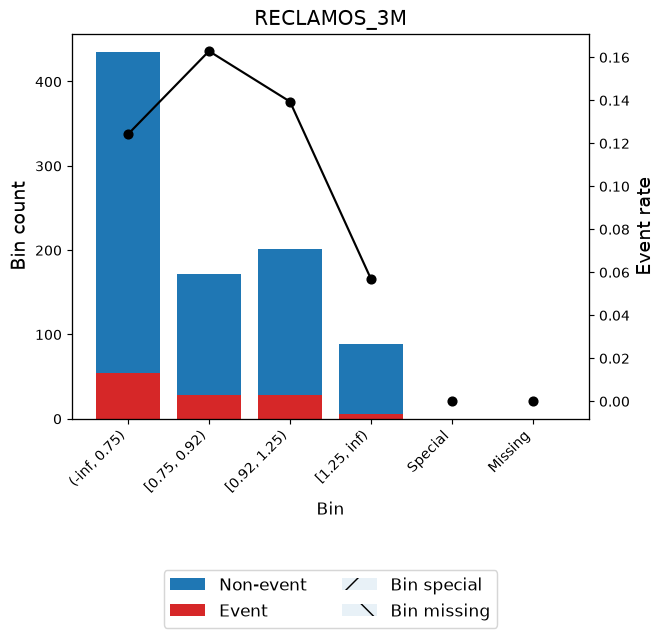

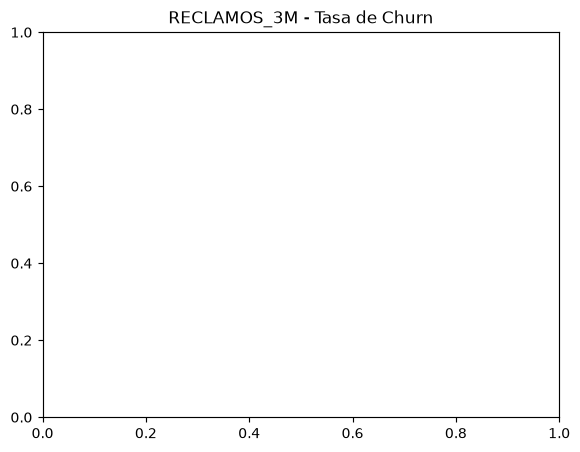

In [83]:
binning_table.plot(metric="event_rate",show_bin_labels=True)
plt.title("RECLAMOS_3M - Tasa de Churn")
plt.show()

In [84]:
print("Information Value:", optb.binning_table.iv)

optb.binning_table.analysis()

Information Value: 0.07533051143469977
---------------------------------------------
OptimalBinning: Binary Binning Table Analysis
---------------------------------------------

  General metrics

    Gini index               0.11879976
    IV (Jeffrey)             0.07533051
    JS (Jensen-Shannon)      0.00918506
    Hellinger                0.00929850
    Triangular               0.03588196
    KS                       0.06279575
    HHI                      0.33252202
    HHI (normalized)         0.11002936
    Cramer's V               0.08273386
    Quality score            0.09828827

  Monotonic trend        peak (concave)

  Significance tests

    Bin A  Bin B  t-statistic  p-value  P[A > B]  P[B > A]
        0      1     1.576139 0.209318  0.112069  0.887931
        1      2     0.400727 0.526714  0.736119  0.263881
        2      3     4.116952 0.042456  0.987720  0.012280



In [ ]:
from sklearn.feature_selection import mutual_info_classif
from optbinning import OptimalBinning


def calcular_mi_iv(df, target):

    # Variables predictoras
    X = df.drop(columns=[target])
    y = df[target]

    # Seleccionar solo variables numéricas para MI
    X_num = X.select_dtypes(include=np.number)

    # Reemplazar infinitos
    X_num = X_num.replace([np.inf, -np.inf], np.nan)

    # Imputación simple para MI
    X_num = X_num.fillna(X_num.median())

    # Mutual Information
    mi = mutual_info_classif(
        X_num,
        y,
        discrete_features=False,
        random_state=42
    )

    mi_df = pd.DataFrame({
        "variable": X_num.columns,
        "mutual_information": mi
    })

    # Information Value
    iv_list = []

    for col in X.columns:
        try:
            x = df[col]

            optb = OptimalBinning(
                name=col,
                dtype="numerical" if pd.api.types.is_numeric_dtype(x) else "categorical"
            )

            optb.fit(x, y)

            iv = optb.binning_table.build()["IV"].iloc[0]

        except Exception:
            iv = np.nan

        iv_list.append({
            "variable": col,
            "information_value": iv
        })

    iv_df = pd.DataFrame(iv_list)

    # Unir MI e IV
    resultado = (
        iv_df
        .merge(mi_df, on="variable", how="left")
        .sort_values(
            ["information_value", "mutual_information"],
            ascending=False
        )
        .reset_index(drop=True)
    )

    return resultado

In [87]:

df_metricas = calcular_mi_iv(df, target="TARGET_CHURN")

print(df_metricas)

                           variable  information_value  mutual_information
0                  DISTRITO_MODE_6M           1.723901                 NaN
1                       DISTRITO_UM           1.318589                 NaN
2                  DISTRITO_MODE_3M           1.209703                 NaN
3         VELOCIDAD_VARIABILIDAD_UM           0.106101            0.016637
4                     CONSUMO_GB_3M           0.091472            0.014343
5                 VELOCIDAD_REAL_UM           0.085994            0.011871
6    INTERACCIONES_DIGITALES_SUM_3M           0.067920            0.016795
7        INTERACCIONES_DIGITALES_3M           0.067920            0.000898
8                     CONSUMO_GB_6M           0.057397            0.004415
9        INTERACCIONES_DIGITALES_UM           0.057110            0.015638
10   INTERACCIONES_DIGITALES_SUM_6M           0.056136            0.012862
11       INTERACCIONES_DIGITALES_6M           0.056136            0.000000
12           PAGOS_ATRASA

SE RECOMIENDA ELIMINAR EL VI CON VALOR 0 NORMALMENTE